# A1 — Medical Appointment No Shows
**Fases 1 y 2: exploración y preparación de los datos**

- Patrón: una cita de un paciente.
- Target: `No-show` (Yes = no acude, No = acude). Clasificación binaria.
- Momento de la predicción: cuando se reserva la cita. Solo se usan datos conocidos en ese momento.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score

SEMILLA = 42                          # semilla fija: los resultados salen siempre iguales
os.makedirs("figures", exist_ok=True)  # carpeta donde se guardan las figuras del report

# Aquí apunto el tamaño de los datos después de cada paso: (paso, filas, columnas)
tamanos = []

## FASE 1 — Exploración
### 1. Carga, tipos, nulos y valores únicos

In [2]:
df = pd.read_csv("data/KaggleV2-May-2016.csv")
print("Tamaño del fichero original:", df.shape)
tamanos.append(("Raw file", df.shape[0], df.shape[1]))

# Textos que podrían estar haciéndose pasar por datos válidos
comodines = ['?', 'NA', 'N/A', 'Unknown', ' ', '', '-']
print("Celdas con comodines:", df.isin(comodines).sum().sum())

resumen = pd.DataFrame({'Tipo': df.dtypes, 'Nulos': df.isna().sum(), 'Únicos': df.nunique()})
print(resumen)

Tamaño del fichero original: (110527, 14)
Celdas con comodines: 0
                   Tipo  Nulos  Únicos
PatientId       float64      0   62299
AppointmentID     int64      0  110527
Gender              str      0       2
ScheduledDay        str      0  103549
AppointmentDay      str      0      27
Age               int64      0     104
Neighbourhood       str      0      81
Scholarship       int64      0       2
Hipertension      int64      0       2
Diabetes          int64      0       2
Alcoholism        int64      0       2
Handcap           int64      0       5
SMS_received      int64      0       2
No-show             str      0       2


### 2. Duplicados
Dos filas iguales en todo excepto `AppointmentID` son la misma cita insertada dos veces.

In [3]:
columnas_sin_id = df.columns.drop('AppointmentID')
#keep first por defecto
print("Filas duplicadas:", df.duplicated(subset=columnas_sin_id).sum())

df_sindup = df.drop_duplicates(subset=columnas_sin_id).copy()
print("Tamaño sin duplicados:", df_sindup.shape)
tamanos.append(("Remove exact duplicates", df_sindup.shape[0], df_sindup.shape[1]))

Filas duplicadas: 618
Tamaño sin duplicados: (109909, 14)


### 3. Fechas: conversión y nuevas variables
- `AwaitingTime_days`: días entre la reserva y la cita.
- `Scheduled_Hour`: hora a la que se reservó.

In [4]:
# Paso las fechas de texto a formato fecha
df_sindup['ScheduledDay_dt'] = pd.to_datetime(df_sindup['ScheduledDay'])
df_sindup['AppointmentDay_dt'] = pd.to_datetime(df_sindup['AppointmentDay'])

# Comprobación: AppointmentDay no trae hora (siempre 00:00:00)
print("Citas con hora distinta de 00:00:00:", (df_sindup['AppointmentDay_dt'].dt.hour != 0).sum())
print("Reservas desde", df_sindup['ScheduledDay_dt'].min().date(), "hasta", df_sindup['ScheduledDay_dt'].max().date())
print("Citas desde", df_sindup['AppointmentDay_dt'].min().date(), "hasta", df_sindup['AppointmentDay_dt'].max().date())

# Días de espera: quito la hora a las dos fechas (normalize) y las resto
dia_reserva = df_sindup['ScheduledDay_dt'].dt.normalize()
dia_cita = df_sindup['AppointmentDay_dt'].dt.normalize()
df_sindup['AwaitingTime_days'] = (dia_cita - dia_reserva).dt.days

# Hora de la reserva
df_sindup['Scheduled_Hour'] = df_sindup['ScheduledDay_dt'].dt.hour

print("Tamaño con las 4 columnas nuevas:", df_sindup.shape)

Citas con hora distinta de 00:00:00: 0
Reservas desde 2015-11-10 hasta 2016-06-08
Citas desde 2016-04-29 hasta 2016-06-08
Tamaño con las 4 columnas nuevas: (109909, 18)


### 4. Valores imposibles
Edad negativa o cita anterior a la reserva. 

In [5]:
print("Edad negativa:", (df_sindup['Age'] < 0).sum())
print("Espera negativa:", (df_sindup['AwaitingTime_days'] < 0).sum())

# Me quedo con las filas que tienen edad >= 0 y espera >= 0
df_filtrado = df_sindup[(df_sindup['Age'] >= 0) & (df_sindup['AwaitingTime_days'] >= 0)].copy()
print("Filas eliminadas:", len(df_sindup) - len(df_filtrado))
print("Tamaño:", df_filtrado.shape)
tamanos.append(("Remove impossible values (+4 date-derived columns)", df_filtrado.shape[0], df_filtrado.shape[1]))

Edad negativa: 1
Espera negativa: 5
Filas eliminadas: 6
Tamaño: (109903, 18)


### 5. Comprobación del valor 0 en Age
Si el 0 fuera un valor de relleno (edad desconocida), habría muchos más pacientes con 0 años que con 1 o 2.

In [6]:
print("Edad 0:", (df_filtrado['Age'] == 0).sum())
print("Edad 1:", (df_filtrado['Age'] == 1).sum())
print("Edad 2:", (df_filtrado['Age'] == 2).sum())

Edad 0: 3530
Edad 1: 2271
Edad 2: 1616


### 6. Distribuciones de las variables de entrada
A partir de aquí uso `df_filtrado` (datos ya limpios).

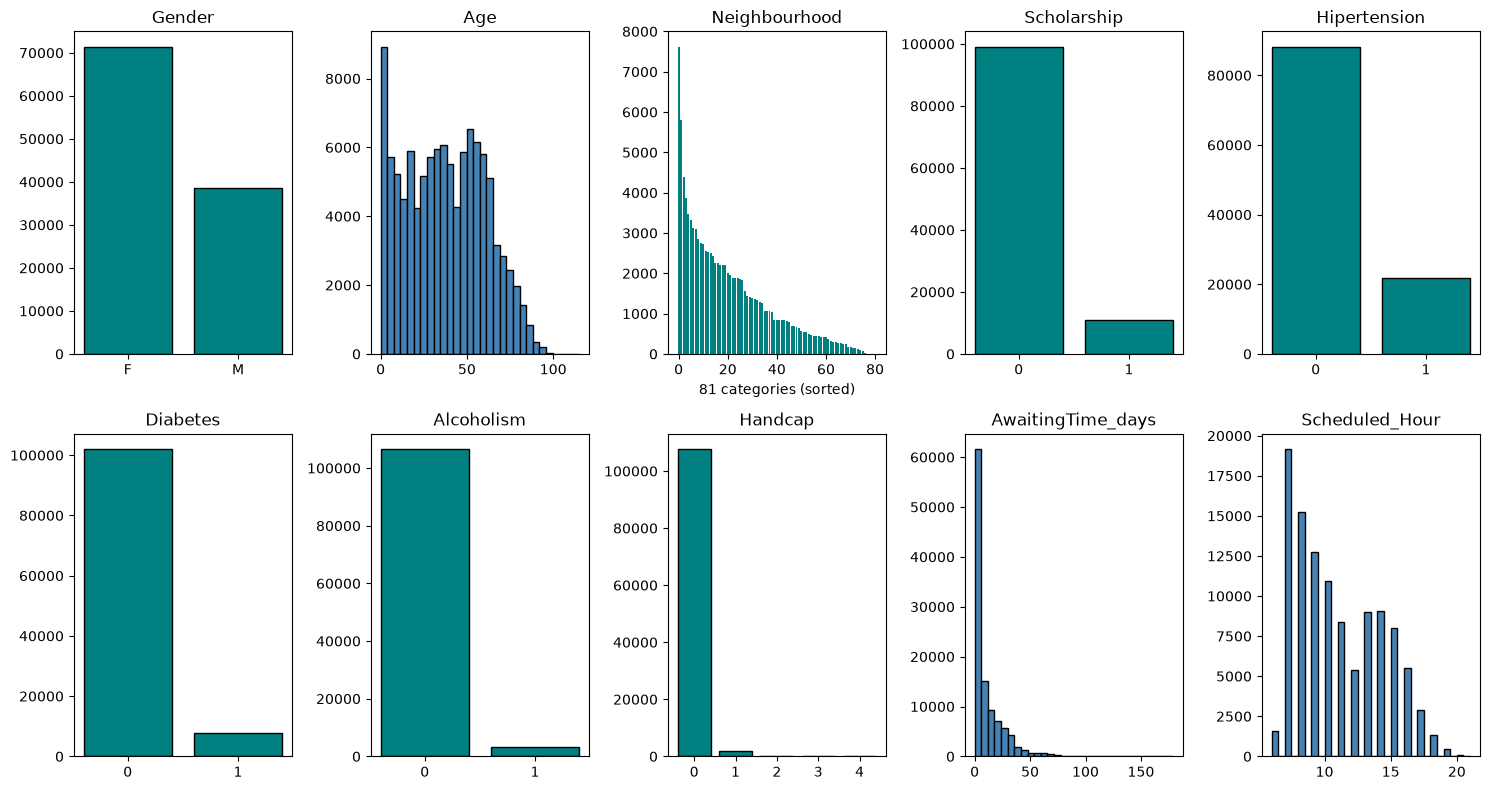

In [7]:
entradas = ['Gender', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension', 'Diabetes',
            'Alcoholism', 'Handcap', 'AwaitingTime_days', 'Scheduled_Hour']
continuas = ['Age', 'AwaitingTime_days', 'Scheduled_Hour']

fig, axes = plt.subplots(2, 5, figsize=(15, 8))
axes = axes.flatten()   # paso la cuadrícula 2x5 a una lista de 10 gráficos

for i, col in enumerate(entradas):
    if col == 'Neighbourhood':
        conteo = df_filtrado[col].value_counts()
        axes[i].bar(range(len(conteo)), conteo.values, color='teal')
        axes[i].set_xlabel("81 categories (sorted)")
    elif col in continuas:
        axes[i].hist(df_filtrado[col], bins=30, color='steelblue', edgecolor='black')
    else:
        conteo = df_filtrado[col].value_counts().sort_index()
        axes[i].bar(conteo.index.astype(str), conteo.values, color='teal', edgecolor='black')
    axes[i].set_title(col)

plt.tight_layout()
plt.savefig("figures/Distribu.png", dpi=150)
plt.show()

In [8]:
print(df_filtrado[continuas].describe().round(2))
print("\nAsimetría:")
print(df_filtrado[continuas].skew().round(2))

             Age  AwaitingTime_days  Scheduled_Hour
count  109903.00          109903.00       109903.00
mean       37.09              10.16           10.77
std        23.12              15.25            3.22
min         0.00               0.00            6.00
25%        18.00               0.00            8.00
50%        37.00               4.00           10.00
75%        55.00              15.00           13.00
max       115.00             179.00           21.00

Asimetría:
Age                  0.12
AwaitingTime_days    2.68
Scheduled_Hour       0.48
dtype: float64


In [9]:
print("Mujeres (%):", round((df_filtrado['Gender'] == 'F').mean() * 100, 2))
for col in ['Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism']:
    print(col, "= 1 (%):", round(df_filtrado[col].mean() * 100, 2))

print("\nHandcap:")
print(df_filtrado['Handcap'].value_counts().sort_index())
print("Handcap = 0 (%):", round((df_filtrado['Handcap'] == 0).mean() * 100, 2))

Mujeres (%): 64.98
Scholarship = 1 (%): 9.83
Hipertension = 1 (%): 19.72
Diabetes = 1 (%): 7.18
Alcoholism = 1 (%): 3.04

Handcap:
Handcap
0    107686
1      2021
2       182
3        11
4         3
Name: count, dtype: int64
Handcap = 0 (%): 97.98


### 7. Distribución del target

         Citas      %
No-show              
No       87803  79.89
Yes      22100  20.11


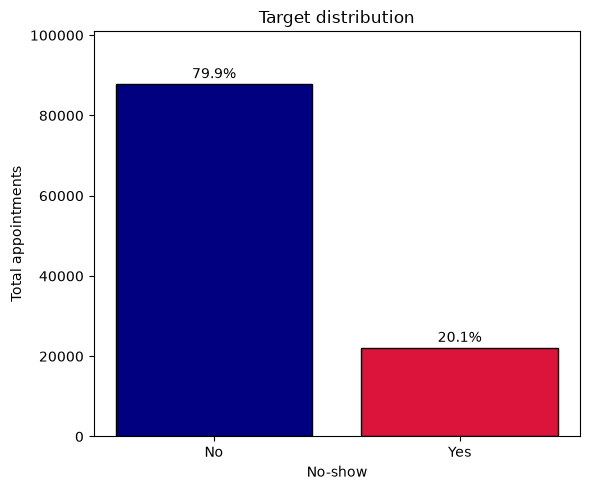

In [10]:
conteo_target = df_filtrado['No-show'].value_counts()
porcentaje_target = df_filtrado['No-show'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Citas': conteo_target, '%': porcentaje_target.round(2)}))

plt.figure(figsize=(6, 5))
plt.bar(conteo_target.index, conteo_target.values, color=['navy', 'crimson'], edgecolor='black')
for i, valor in enumerate(conteo_target.index):
    plt.text(i, conteo_target[valor] + 1500, f"{porcentaje_target[valor]:.1f}%", ha='center')
plt.title("Target distribution")
plt.xlabel("No-show")
plt.ylabel("Total appointments")
plt.ylim(0, conteo_target.max() * 1.15)
plt.tight_layout()
plt.savefig("figures/Target_dist.png", dpi=150)
plt.show()

### 8. Correlación entre variables de entrada
`Gender` es texto (F/M), así que en una copia lo paso a número (F = 0, M = 1) solo para este cálculo.

                   Gender_num   Age  Scholarship  Hipertension  Diabetes  \
Gender_num               1.00 -0.11        -0.11         -0.06     -0.03   
Age                     -0.11  1.00        -0.09          0.50      0.29   
Scholarship             -0.11 -0.09         1.00         -0.02     -0.02   
Hipertension            -0.06  0.50        -0.02          1.00      0.43   
Diabetes                -0.03  0.29        -0.02          0.43      1.00   
Alcoholism               0.11  0.10         0.03          0.09      0.02   
Handcap                  0.02  0.08        -0.01          0.08      0.06   
AwaitingTime_days       -0.03  0.03        -0.03         -0.02     -0.03   
Scheduled_Hour          -0.00  0.01        -0.02         -0.03     -0.01   

                   Alcoholism  Handcap  AwaitingTime_days  Scheduled_Hour  
Gender_num               0.11     0.02              -0.03           -0.00  
Age                      0.10     0.08               0.03            0.01  
Scholarship

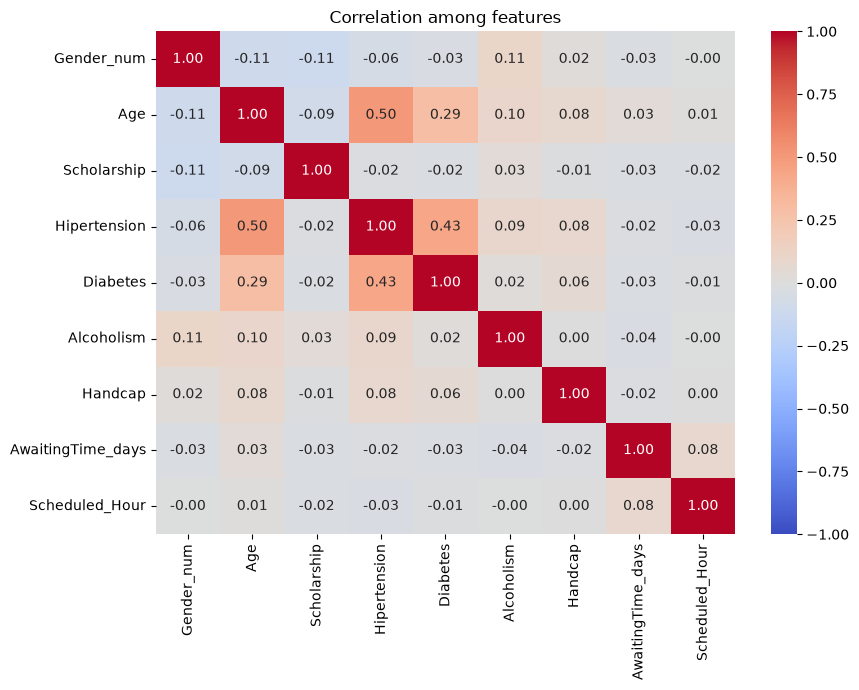

In [11]:
df_corr = df_filtrado.copy()
df_corr['Gender_num'] = df_corr['Gender'].map({'F': 0, 'M': 1})

columnas_corr = ['Gender_num', 'Age', 'Scholarship', 'Hipertension', 'Diabetes',
                 'Alcoholism', 'Handcap', 'AwaitingTime_days', 'Scheduled_Hour']
matriz_corr = df_corr[columnas_corr].corr()
print(matriz_corr.round(2))

plt.figure(figsize=(9, 7))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation among features")
plt.tight_layout()
plt.savefig("figures/Correlation.png", dpi=150)
plt.show()

### 9. ¿Se conoce `SMS_received` al reservar?
Miro su relación con la espera.

In [12]:
espera_corta = df_filtrado[df_filtrado['AwaitingTime_days'] <= 1]
espera_larga = df_filtrado[df_filtrado['AwaitingTime_days'] > 1]
sms_corta = espera_corta['SMS_received'].sum()
sms_larga = espera_larga['SMS_received'].sum()

print("Espera <= 1 días:", sms_corta, "citas con SMS de", len(espera_corta),
      "->", round(sms_corta / len(espera_corta) * 100, 1), "%")
print("Espera  > 1 días:", sms_larga, "citas con SMS de", len(espera_larga),
      "->", round(sms_larga / len(espera_larga) * 100, 1), "%")

Espera <= 1 días: 0 citas con SMS de 43656 -> 0.0 %
Espera  > 1 días: 35482 citas con SMS de 66247 -> 53.6 %


## FASE 2 — Preparación de los datos
### 10. Una cita por paciente y muestra de 20.000
Toda la limpieza (pasos 2 a 11) se hace sobre el dataset completo, como en el LAB01a; el split se hace al final, con los datos ya limpios.
Las citas de un mismo paciente no son independientes. Me quedo con una cita al azar de cada paciente y después saco una muestra estratificada de 20.000.

In [13]:
print("Pacientes distintos:", df_filtrado['PatientId'].nunique())

df_barajado = df_filtrado.sample(frac=1, random_state=SEMILLA)
df_un_paciente = df_barajado.drop_duplicates(subset='PatientId').copy()
print("Una cita por paciente:", df_un_paciente.shape)
tamanos.append(("One random appointment per patient", df_un_paciente.shape[0], df_un_paciente.shape[1]))

df_muestra, _ = train_test_split(df_un_paciente, train_size=20000,
                                 stratify=df_un_paciente['No-show'], random_state=SEMILLA)
print("Muestra:", df_muestra.shape)
tamanos.append(("Stratified sample", df_muestra.shape[0], df_muestra.shape[1]))

Pacientes distintos: 62298
Una cita por paciente: (62298, 18)
Muestra: (20000, 18)


In [14]:
# Compruebo que las distribuciones no cambian al quedarme con una cita por paciente y al muestrear
nombres = ['All valid appointments', 'One per patient', 'Sample']
conjuntos = [df_filtrado, df_un_paciente, df_muestra]

for nombre, datos in zip(nombres, conjuntos):
    print(nombre)
    print("  Filas:", len(datos))
    print("  No-show = Yes (%):", round((datos['No-show'] == 'Yes').mean() * 100, 2))
    print("  Mujeres (%):", round((datos['Gender'] == 'F').mean() * 100, 2))
    print("  Edad media:", round(datos['Age'].mean(), 2))
    print("  Espera mediana / media (días):", datos['AwaitingTime_days'].median(), "/", round(datos['AwaitingTime_days'].mean(), 2))
    print("  Hipertensión / Diabetes (%):", round(datos['Hipertension'].mean() * 100, 2), "/", round(datos['Diabetes'].mean() * 100, 2))

All valid appointments
  Filas: 109903
  No-show = Yes (%): 20.11
  Mujeres (%): 64.98
  Edad media: 37.09
  Espera mediana / media (días): 4.0 / 10.16
  Hipertensión / Diabetes (%): 19.72 / 7.18
One per patient
  Filas: 62298
  No-show = Yes (%): 19.76
  Mujeres (%): 64.28
  Edad media: 36.71
  Espera mediana / media (días): 4.0 / 11.2
  Hipertensión / Diabetes (%): 19.65 / 7.09
Sample
  Filas: 20000
  No-show = Yes (%): 19.76
  Mujeres (%): 64.52
  Edad media: 36.71
  Espera mediana / media (días): 4.0 / 11.26
  Hipertensión / Diabetes (%): 19.7 / 7.28


### 11. Outliers (regla IQR, sobre la muestra limpia, antes del split)
Outlier = valor fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]. Solo se cuentan y se miran: no se elimina ni se transforma nada, así que no se aprende ningún parámetro.

Age -> outliers: 1 | máximo: 115
AwaitingTime_days -> outliers: 971 | máximo: 179
Scheduled_Hour -> outliers: 1 | máximo: 21


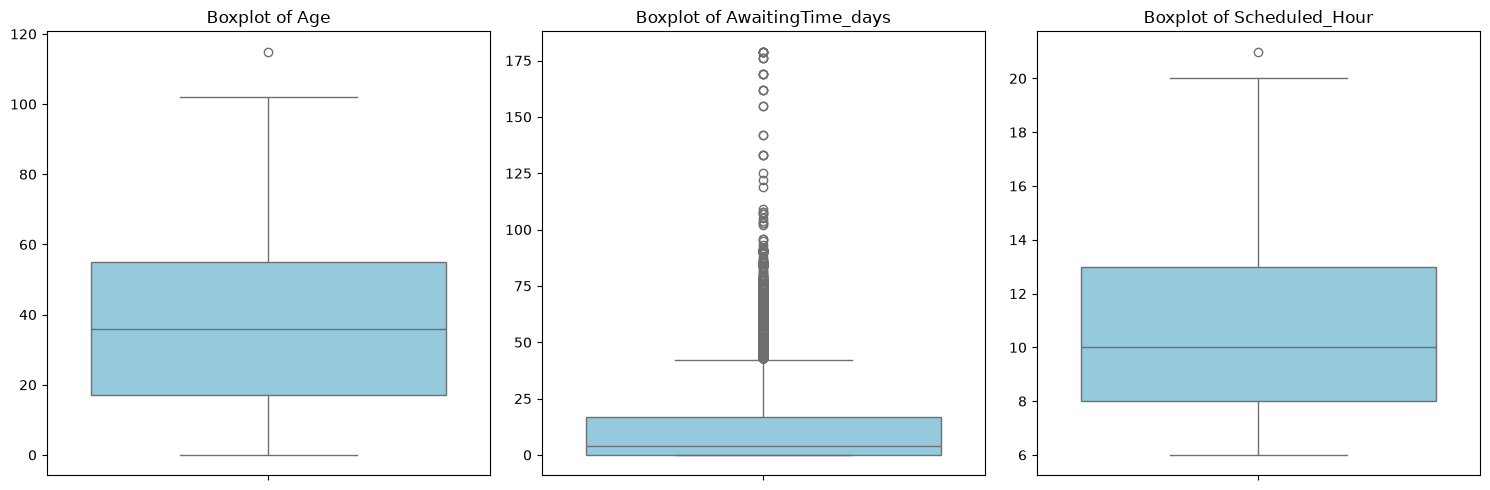

In [15]:
for col in continuas:
    Q1 = df_muestra[col].quantile(0.25)
    Q3 = df_muestra[col].quantile(0.75)
    IQR = Q3 - Q1
    fuera = (df_muestra[col] < Q1 - 1.5 * IQR) | (df_muestra[col] > Q3 + 1.5 * IQR)
    print(col, "-> outliers:", fuera.sum(), "| máximo:", df_muestra[col].max())

plt.figure(figsize=(15, 5))
for i, col in enumerate(continuas):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df_muestra[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.ylabel('')
plt.tight_layout()
plt.savefig("figures/Diag_cajas.png", dpi=150)
plt.show()

### 12. Relación de cada variable con el target (muestra de 20.000, antes del split)
Es solo descriptivo: no se usa para elegir ni quitar ninguna variable, así que no pasa información del test al modelo.

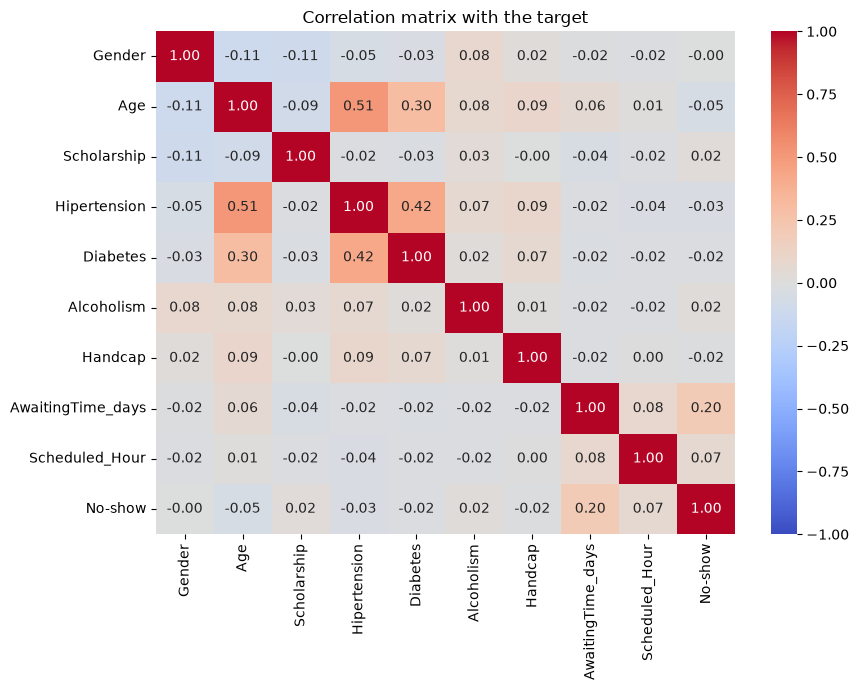

Age                 -0.054
Hipertension        -0.035
Diabetes            -0.017
Handcap             -0.015
Gender              -0.004
Alcoholism           0.021
Scholarship          0.024
Scheduled_Hour       0.068
AwaitingTime_days    0.202
Name: No-show, dtype: float64


In [16]:
# Copia de la muestra solo para este cálculo: Gender a número y el target como una columna más
columnas_rel = ['Gender', 'Age', 'Scholarship', 'Hipertension', 'Diabetes',
                'Alcoholism', 'Handcap', 'AwaitingTime_days', 'Scheduled_Hour']
muestra_corr = df_muestra[columnas_rel].copy()
muestra_corr['Gender'] = muestra_corr['Gender'].map({'F': 0, 'M': 1})
muestra_corr['No-show'] = (df_muestra['No-show'] == 'Yes').astype(int)   # Yes = 1, No = 0

matriz_target = muestra_corr.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(matriz_target, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation matrix with the target")
plt.tight_layout()
plt.savefig("figures/Correlation_target.png", dpi=150)
plt.show()

print(matriz_target['No-show'].drop('No-show').round(3).sort_values())

In [17]:
tramos = pd.cut(df_muestra['AwaitingTime_days'], bins=[-1, 0, 3, 7, 15, 30, 200],
                labels=['0', '1-3', '4-7', '8-15', '16-30', '>30'])

citas_por_tramo = tramos.value_counts(sort=False)

no_shows_por_tramo = tramos[df_muestra['No-show'] == 'Yes'].value_counts(sort=False)

porcentaje_no_show = no_shows_por_tramo / citas_por_tramo * 100

print(pd.DataFrame({'Citas': citas_por_tramo,
                    'No-shows (Yes)': no_shows_por_tramo,
                    'No-show (%)': porcentaje_no_show.round(1)}))

                   Citas  No-shows (Yes)  No-show (%)
AwaitingTime_days                                    
0                   6946             238          3.4
1-3                 2531             578         22.8
4-7                 2814             681         24.2
8-15                2313             681         29.4
16-30               3128            1008         32.2
>30                 2268             765         33.7


### 13. Separar target, quitar columnas y split 60/20/20 (al final de la limpieza)
A partir de aquí, todo lo que aprende de los datos (escaladores y encoders) se ajusta solo con train dentro de un `Pipeline`.

In [18]:
y = df_muestra['No-show']

columnas_a_quitar = [
    'No-show',
    'PatientId', 'AppointmentID',
    'SMS_received',
    'ScheduledDay', 'AppointmentDay',
    'ScheduledDay_dt', 'AppointmentDay_dt'
]
X = df_muestra.drop(columns=columnas_a_quitar)
print("Variables de entrada:", X.columns.tolist())
tamanos.append(("Inputs only (target, identifiers, SMS and raw dates dropped)", X.shape[0], X.shape[1]))

# 1º separo el test (20 %). 2º, del 80 % que queda, separo validación (25 % de 80 % = 20 % del total)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEMILLA)
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)


print("No-shows (Yes) -> train:", (y_train == 'Yes').sum(), "| val:", (y_val == 'Yes').sum(), "| test:", (y_test == 'Yes').sum())


# Target en 0/1 para los modelos (Yes = 1, No = 0)
y_train_bin = (y_train == 'Yes').astype(int)
y_val_bin = (y_val == 'Yes').astype(int)
y_test_bin = (y_test == 'Yes').astype(int)




Variables de entrada: ['Gender', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'AwaitingTime_days', 'Scheduled_Hour']
Train: (12000, 10) | Val: (4000, 10) | Test: (4000, 10)
No-shows (Yes) -> train: 2371 | val: 790 | test: 790


### 14. Neighbourhood: barrios frecuentes y poco frecuentes (solo en train)

In [19]:
frecuencia = X_train['Neighbourhood'].value_counts(normalize=True)
barrios_raros = frecuencia[frecuencia < 0.01].index

print("Barrios en el fichero original:", df['Neighbourhood'].nunique())
print("Barrios en train:", len(frecuencia))
print("Barrios con >= 1 % (columna propia):", (frecuencia >= 0.01).sum())
print("Barrios con < 1 % (se agrupan):", len(barrios_raros))
print("Peso de los barrios agrupados (%):", round(frecuencia[barrios_raros].sum() * 100, 2))

# Barrio del fichero que no ha entrado en la muestra
for barrio in df['Neighbourhood'].unique():
    if barrio not in X['Neighbourhood'].values:
        print("No está en la muestra:", barrio, "-> filas en el fichero original:", (df['Neighbourhood'] == barrio).sum())

Barrios en el fichero original: 81
Barrios en train: 80
Barrios con >= 1 % (columna propia): 37
Barrios con < 1 % (se agrupan): 43
Peso de los barrios agrupados (%): 17.68
No está en la muestra: ILHAS OCEÂNICAS DE TRINDADE -> filas en el fichero original: 2


### 15. Decisión medida: ¿agrupar los barrios poco frecuentes?
- **Opción A:** one-hot agrupando los barrios con menos del 1 % en una sola columna.
- **Opción B:** one-hot con una columna por barrio.

Mismo modelo de prueba (regresión logística), entrenado en train y evaluado en validación. El test no se toca.

**Métrica: precisión.** La acción sería dar la cita de un posible no-show a otro paciente. Un falso positivo hace que vengan dos pacientes a la misma hora, así que importa sobre todo que, cuando el modelo dice *no-show*, acierte. Muestro también cuántas citas marca y el recall, para comprobar que la precisión no sube solo porque marque menos citas.

In [20]:
columnas_binarias = ['Gender', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism']

preprocesador_A = ColumnTransformer([
    ('estandar', StandardScaler(), ['Age', 'Scheduled_Hour']),          # simétricas, sin outliers
    ('robusto', RobustScaler(), ['AwaitingTime_days', 'Handcap']),      # asimétrica con outliers / casi siempre 0
    ('bin', OneHotEncoder(drop='if_binary', sparse_output=False), columnas_binarias),
    ('barrio', OneHotEncoder(min_frequency=0.01, handle_unknown='ignore', sparse_output=False), ['Neighbourhood'])
])

preprocesador_B = ColumnTransformer([
    ('estandar', StandardScaler(), ['Age', 'Scheduled_Hour']),          # simétricas, sin outliers
    ('robusto', RobustScaler(), ['AwaitingTime_days', 'Handcap']),
    ('bin', OneHotEncoder(drop='if_binary', sparse_output=False), columnas_binarias),
    ('barrio', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Neighbourhood'])
])

In [21]:

# OPCIÓN A
pipeline_A = Pipeline([
    ('prep', preprocesador_A),
    ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEMILLA))
])
pipeline_A.fit(X_train, y_train_bin)
pred_A = pipeline_A.predict(X_val)

# OPCIÓN B
pipeline_B = Pipeline([
    ('prep', preprocesador_B),
    ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEMILLA))
])
pipeline_B.fit(X_train, y_train_bin)
pred_B = pipeline_B.predict(X_val)

# Número de columnas que genera cada preprocesador
print("Features opción A:", len(pipeline_A.named_steps['prep'].get_feature_names_out()))
print("Features opción B:", len(pipeline_B.named_steps['prep'].get_feature_names_out()))

Features opción A: 47
Features opción B: 89


In [22]:

for nombre, pred in [('A', pred_A), ('B', pred_B)]:
    print("Opción", nombre)
    print("  Precisión:", round(precision_score(y_val_bin, pred), 4))
    print("  Citas marcadas como no-show:", (pred == 1).sum())
    print("  Falsos positivos (acude, pero se predijo no-show):", ((pred == 1) & (y_val_bin == 0)).sum())
    print("  Falsos negativos (no acude y no se detectó):", ((pred == 0) & (y_val_bin == 1)).sum())
    print("  Recall:", round(recall_score(y_val_bin, pred), 4))

Opción A
  Precisión: 0.321
  Citas marcadas como no-show: 1458
  Falsos positivos (acude, pero se predijo no-show): 990
  Falsos negativos (no acude y no se detectó): 322
  Recall: 0.5924
Opción B
  Precisión: 0.3208
  Citas marcadas como no-show: 1465
  Falsos positivos (acude, pero se predijo no-show): 995
  Falsos negativos (no acude y no se detectó): 320
  Recall: 0.5949


In [23]:

en_barrio_raro = X_val['Neighbourhood'].isin(barrios_raros).values
print("Citas de validación en barrios agrupados:", en_barrio_raro.sum())
print("Precisión en esos barrios -> A:", round(precision_score(y_val_bin[en_barrio_raro], pred_A[en_barrio_raro]), 4),
      "| B:", round(precision_score(y_val_bin[en_barrio_raro], pred_B[en_barrio_raro]), 4))

Citas de validación en barrios agrupados: 714
Precisión en esos barrios -> A: 0.2816 | B: 0.2811


In [24]:
barrios_train = X_train['Neighbourhood']

citas_por_barrio = barrios_train.value_counts()                         # total de citas por barrio
no_shows_por_barrio = barrios_train[y_train == 'Yes'].value_counts()    # solo citas con No-show = 'Yes'

tabla = pd.DataFrame({'Citas': citas_por_barrio,
                      'No-shows (Yes)': no_shows_por_barrio}).fillna(0).astype(int)  # barrio sin no-shows -> 0
tabla['No-show (%)'] = (tabla['No-shows (Yes)'] / tabla['Citas'] * 100).round(1)

agrupados = tabla.loc[barrios_raros]
print(agrupados.sort_values('No-show (%)', ascending=False).head(5))
print("\nNo-show en todo train (%):", round(y_train_bin.mean() * 100, 2))

                Citas  No-shows (Yes)  No-show (%)
Neighbourhood                                     
ILHA DO FRADE       1               1        100.0
NAZARETH           19               7         36.8
DO MOSCOSO         39              14         35.9
BARRO VERMELHO     46              12         26.1
JUCUTUQUARA        74              19         25.7

No-show en todo train (%): 19.76


### 16. Preprocesado final (opción A) y forma final de los datos

In [25]:

prep_final = pipeline_A.named_steps['prep']
X_train_prep = prep_final.transform(X_train)
X_val_prep = prep_final.transform(X_val)
X_test_prep = prep_final.transform(X_test)

print("X_train_prep:", X_train_prep.shape, "| X_val_prep:", X_val_prep.shape, "| X_test_prep:", X_test_prep.shape)
tamanos.append(("After encoding (train / val / test)",
                f"{X_train_prep.shape[0]} / {X_val_prep.shape[0]} / {X_test_prep.shape[0]}", X_train_prep.shape[1]))

print(pd.DataFrame(tamanos, columns=['Step', 'Rows', 'Columns']).to_string(index=False))

X_train_prep: (12000, 47) | X_val_prep: (4000, 47) | X_test_prep: (4000, 47)
                                                        Step                Rows  Columns
                                                    Raw file              110527       14
                                     Remove exact duplicates              109909       14
          Remove impossible values (+4 date-derived columns)              109903       18
                          One random appointment per patient               62298       18
                                           Stratified sample               20000       18
Inputs only (target, identifiers, SMS and raw dates dropped)               20000       10
                         After encoding (train / val / test) 12000 / 4000 / 4000       47


**Para la Fase 3:** cada modelo irá en un `Pipeline` con `preprocesador_A`, igual que en el paso 15: `fit` con `X_train`, comparación de hiperparámetros con `X_val` y el test (`X_test`) una sola vez, al final.

## FASE 3 — Pregunta y comparación de modelos
**Pregunta:** en el momento de reservar una cita, ¿el paciente acudirá o no? (clasificación binaria, `No-show = Yes` = 1).

**Métrica: precisión.** Si marco una cita como no-show y le doy el hueco a otro paciente, un falso positivo significa dos pacientes a la vez. Todavía no sé cómo medir la precisión de forma justa: primero pruebo una lista de umbrales con cada modelo (paso 17) y con lo que vea decido (paso 18).

Los hiperparámetros se eligen en validación. El test se usa una sola vez, al final.

In [26]:
import numpy as np
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score   # AP = área bajo la curva precisión-recall

# Uso clone(preprocesador_A) para que cada modelo tenga su propio preprocesador, que aprende solo de su train.

### 17. Primera prueba: precisión con una lista de umbrales (modelos por defecto, validación)
`predict()` dice "no-show" cuando la probabilidad es 0,5 o más, pero no sé si 0,5 tiene sentido para estos modelos.
Entreno cada modelo con sus valores por defecto y pruebo umbrales de 0,05 a 0,95 (de 0,05 en 0,05): para cada uno miro cuántas citas se marcan y con qué precisión y recall.

Logistic regression (balanced)
 umbral  marcadas  precisión  recall
   0.05      4000      0.198   1.000
   0.10      4000      0.198   1.000
   0.15      4000      0.198   1.000
   0.20      4000      0.198   1.000
   0.25      3952      0.199   0.997
   0.30      3759      0.205   0.976
   0.35      3348      0.219   0.928
   0.40      2662      0.247   0.832
   0.45      1998      0.286   0.724
   0.50      1458      0.321   0.592
   0.55      1070      0.333   0.451
   0.60       753      0.361   0.344
   0.65       505      0.378   0.242
   0.70       324      0.370   0.152
   0.75       181      0.365   0.084
   0.80        99      0.354   0.044
   0.85        48      0.417   0.025
   0.90        17      0.412   0.009
   0.95         6      0.500   0.004

Random forest (defaults)
 umbral  marcadas  precisión  recall
   0.05      2869      0.257   0.932
   0.10      2477      0.277   0.868
   0.15      2127      0.288   0.776
   0.20      1775      0.297   0.668
   0.25      1426 

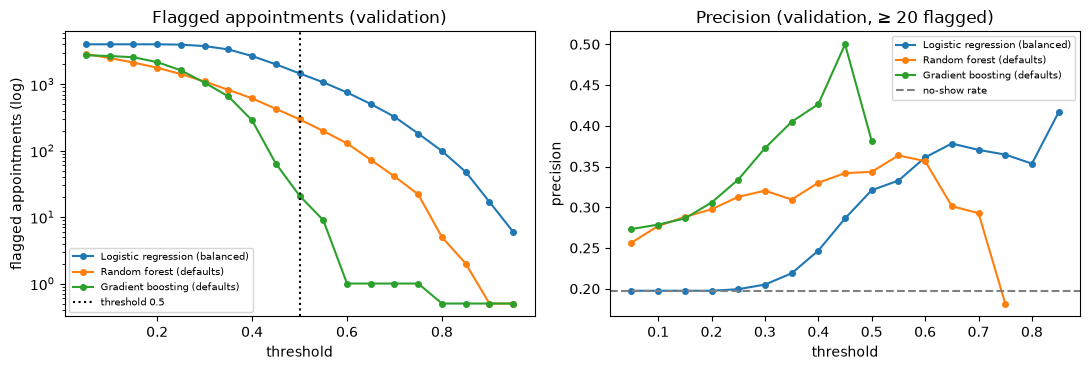

In [27]:
modelos_defecto = {
    'Logistic regression (balanced)': LogisticRegression(class_weight='balanced', max_iter=2000),
    'Random forest (defaults)': RandomForestClassifier(n_jobs=-1, random_state=SEMILLA),
    'Gradient boosting (defaults)': GradientBoostingClassifier(random_state=SEMILLA),
}
umbrales = np.round(np.arange(0.05, 0.96, 0.05), 2)

prob_val_defecto = {}
tablas_umbral = {}
for nombre, modelo in modelos_defecto.items():
    pipe = Pipeline([('prep', clone(preprocesador_A)), ('modelo', modelo)])
    pipe.fit(X_train, y_train_bin)
    prob_val = pipe.predict_proba(X_val)[:, 1]
    prob_val_defecto[nombre] = prob_val

    marcadas, precisiones, recalls = [], [], []
    for u in umbrales:
        pred = (prob_val >= u).astype(int)
        marcadas.append(pred.sum())
        precisiones.append(precision_score(y_val_bin, pred, zero_division=0))
        recalls.append(recall_score(y_val_bin, pred))

    tabla = pd.DataFrame({'umbral': umbrales, 'marcadas': marcadas, 'precisión': precisiones, 'recall': recalls})
    tablas_umbral[nombre] = tabla
    print(nombre)
    print(tabla.round(3).to_string(index=False))
    print()

# Figura: citas marcadas y precisión para cada umbral
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for nombre in modelos_defecto:
    tabla = tablas_umbral[nombre]
    #  citas marcadas. En escala logarítmica el 0 no existe, así que dibujo 0 citas como 0.5 (abajo del todo)
    axes[0].plot(tabla['umbral'], tabla['marcadas'].clip(lower=0.5), 'o-', label=nombre, markersize=4)
    #  precisión, solo en los umbrales con al menos 20 citas marcadas
    con_citas = tabla[tabla['marcadas'] >= 20]
    axes[1].plot(con_citas['umbral'], con_citas['precisión'], 'o-', label=nombre, markersize=4)
axes[0].axvline(0.5, color='black', linestyle=':', label='threshold 0.5')
axes[0].set_yscale('log'); axes[0].set_xlabel('threshold'); axes[0].set_ylabel('flagged appointments (log)')
axes[0].set_title('Flagged appointments (validation)'); axes[0].legend(fontsize=7)
axes[1].axhline(y_val_bin.mean(), color='grey', linestyle='--', label='no-show rate')
axes[1].set_xlabel('threshold'); axes[1].set_ylabel('precision'); axes[1].set_title('Precision (validation, ≥ 20 flagged)')
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig("figures/Thresholds.png", dpi=150)
plt.show()

### 18. Decisión: precisión en el 10 % de citas con más riesgo
Con el mismo umbral cada modelo marca un número de citas muy distinto, así que sus precisiones no se pueden comparar (con menos citas marcadas la precisión puede subir sola).
Por eso cada modelo ordena las citas por su probabilidad y se marcan las 10 % más arriesgadas (400 de 4.000). Es lo mismo que darle a cada modelo el umbral que marca 400 citas.


In [28]:
# Esta es la única función de la fase 3: la métrica. La uso en todos los pasos siguientes.
def precision_top10(probabilidades, y_real):
    n_marcadas = int(round(0.10 * len(y_real)))
    mas_riesgo = np.argsort(-probabilidades)[:n_marcadas]
    return y_real.values[mas_riesgo].mean()

for nombre in modelos_defecto:
    print(nombre, "-> precisión top 10 %:", round(precision_top10(prob_val_defecto[nombre], y_val_bin), 3))

Logistic regression (balanced) -> precisión top 10 %: 0.385
Random forest (defaults) -> precisión top 10 %: 0.345
Gradient boosting (defaults) -> precisión top 10 %: 0.428


### 19. Baseline: un clasificador que no aprende nada

In [29]:
dummy = Pipeline([('prep', clone(preprocesador_A)),
                  ('modelo', DummyClassifier(strategy='prior'))])   # da a todas las citas la misma probabilidad
dummy.fit(X_train, y_train_bin)
prob_val = dummy.predict_proba(X_val)[:, 1]
print("Dummy -> precisión top 10 % en validación:", round(precision_top10(prob_val, y_val_bin), 3))


Dummy -> precisión top 10 % en validación: 0.19


### 20. Modelo 1: regresión logística (lineal)
**Por qué y qué espero (antes de ejecutarlo):** es el modelo más simple que tiene sentido: una suma ponderada de las 47 features pasada por una sigmoide. Espero que supere claramente al baseline, porque el tiempo de espera y la edad están relacionados con el no-show (paso 12), y que no tenga sobreajuste (pocos coeficientes y muchos datos). Pero espero que se quede corto: el efecto del tiempo de espera no es una recta (salto entre 0 y 1 día).
Hiperparámetro **C**: la regularización L2 es λ = 1/C. C pequeño = coeficientes más pequeños.

In [30]:
valores_C = [0.001, 0.01, 0.1, 1, 10]
lr_train, lr_val = [], []
for C in valores_C:
    modelo = Pipeline([('prep', clone(preprocesador_A)),
                       ('modelo', LogisticRegression(C=C, class_weight='balanced', max_iter=2000))])
    modelo.fit(X_train, y_train_bin)
    prob_train = modelo.predict_proba(X_train)[:, 1]
    prob_val = modelo.predict_proba(X_val)[:, 1]
    lr_train.append(precision_top10(prob_train, y_train_bin))
    lr_val.append(precision_top10(prob_val, y_val_bin))
print(pd.DataFrame({'C': valores_C, 'train': lr_train, 'validación': lr_val}).round(3).to_string(index=False))

     C  train  validación
 0.001  0.338       0.372
 0.010  0.344       0.378
 0.100  0.359       0.388
 1.000  0.358       0.385
10.000  0.358       0.385


In [31]:
X_train_mismo_dia = X_train.copy()
X_val_mismo_dia = X_val.copy()
X_train_mismo_dia['SameDay'] = (X_train['AwaitingTime_days'] == 0).astype(int)
X_val_mismo_dia['SameDay'] = (X_val['AwaitingTime_days'] == 0).astype(int)

# El mismo preprocesador A, añadiendo SameDay a las columnas binarias
prep_mismo_dia = ColumnTransformer([
    ('estandar', StandardScaler(), ['Age', 'Scheduled_Hour']),
    ('robusto', RobustScaler(), ['AwaitingTime_days', 'Handcap']),
    ('bin', OneHotEncoder(drop='if_binary', sparse_output=False), columnas_binarias + ['SameDay']),
    ('barrio', OneHotEncoder(min_frequency=0.01, handle_unknown='ignore', sparse_output=False), ['Neighbourhood'])
])
lr_mismo_dia = Pipeline([('prep', prep_mismo_dia),
                         ('modelo', LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000))])
lr_mismo_dia.fit(X_train_mismo_dia, y_train_bin)
prob_val = lr_mismo_dia.predict_proba(X_val_mismo_dia)[:, 1]
print("Regresión logística + 'mismo día' -> validación:", round(precision_top10(prob_val, y_val_bin), 3))

Regresión logística + 'mismo día' -> validación: 0.402


In [ ]:
# penalización L1 frente a L2.
lr_l1_val, lr_l2_val, lr_l1_no_cero = [], [], []
for C in valores_C:
    # L1
    modelo_l1 = Pipeline([('prep', clone(preprocesador_A)),
                          ('modelo', LogisticRegression(C=C, l1_ratio=1, solver='liblinear',
                                                        class_weight='balanced', max_iter=2000))])
    modelo_l1.fit(X_train, y_train_bin)
    lr_l1_val.append(precision_top10(modelo_l1.predict_proba(X_val)[:, 1], y_val_bin))
    coeficientes = modelo_l1.named_steps['modelo'].coef_[0]
    lr_l1_no_cero.append(int((coeficientes != 0).sum()))
    if C == 0.001:
        nombres = modelo_l1.named_steps['prep'].get_feature_names_out()
        print("L1 con C = 0.001 -> coeficientes distintos de 0:", list(nombres[coeficientes != 0]))

    # L2
    modelo_l2 = Pipeline([('prep', clone(preprocesador_A)),
                          ('modelo', LogisticRegression(C=C, l1_ratio=0, solver='liblinear',
                                                        class_weight='balanced', max_iter=2000))])
    modelo_l2.fit(X_train, y_train_bin)
    lr_l2_val.append(precision_top10(modelo_l2.predict_proba(X_val)[:, 1], y_val_bin))

print(pd.DataFrame({'C': valores_C, 'L1 validación': lr_l1_val, 'coeficientes ≠ 0 (L1)': lr_l1_no_cero,
                    'L2 validación': lr_l2_val}).round(3).to_string(index=False))


L1 con C = 0.001 -> coeficientes distintos de 0: ['robusto__AwaitingTime_days']
     C  L1 validación  coeficientes ≠ 0 (L1)  L2 validación
 0.001          0.348                      1          0.365
 0.010          0.358                      3          0.380
 0.100          0.370                     20          0.388
 1.000          0.380                     44          0.385
10.000          0.385                     45          0.385


### 21. Modelo 2: random forest
**Por qué y qué espero (antes de ejecutarlo):** los árboles cortan las variables con umbrales ("¿espera ≤ 0 días?"), así que pueden captar el salto del tiempo de espera sin crear features nuevas, y no necesitan escalado. Promediar muchos árboles reduce la varianza. Espero que sea mejor que la regresión logística, pero que con árboles completos memorice el train (sobreajuste) y haya que limitar el tamaño de las hojas.
Hiperparámetros principales: **min_samples_leaf** (tamaño de cada árbol), **max_features** (variables por pregunta) y **n_estimators** (número de árboles).

In [33]:
# 1. Tamaño mínimo de las hojas: 1 = árboles completos (memorizan train)
valores_hoja = [1, 2, 5, 10, 20, 50, 100, 200, 300, 400, 500]
rf_train, rf_val, rf_oob = [], [], []
for hoja in valores_hoja:
    modelo = Pipeline([('prep', clone(preprocesador_A)),
                       ('modelo', RandomForestClassifier(n_estimators=300, min_samples_leaf=hoja,
                                                         oob_score=True, n_jobs=-1, random_state=SEMILLA))])
    modelo.fit(X_train, y_train_bin)
    rf_train.append(precision_top10(modelo.predict_proba(X_train)[:, 1], y_train_bin))
    rf_val.append(precision_top10(modelo.predict_proba(X_val)[:, 1], y_val_bin))
    rf_oob.append(modelo.named_steps['modelo'].oob_score_)   # accuracy out-of-bag
print(pd.DataFrame({'min_samples_leaf': valores_hoja, 'train': rf_train, 'validación': rf_val,
                    'accuracy OOB': rf_oob}).round(3).to_string(index=False))

 min_samples_leaf  train  validación  accuracy OOB
                1  1.000       0.345         0.782
                2  0.982       0.375         0.801
                5  0.732       0.400         0.803
               10  0.584       0.415         0.802
               20  0.499       0.400         0.802
               50  0.458       0.432         0.802
              100  0.434       0.440         0.802
              200  0.424       0.440         0.802
              300  0.412       0.442         0.802
              400  0.408       0.438         0.802
              500  0.402       0.432         0.802


In [34]:
# 2. Variables por pregunta ('sqrt' = raíz del nº de variables; 1.0 = todas)
valores_max_feat = ['sqrt', 0.3, 0.5, 1.0]
rf_max_feat_val = []
for max_feat in valores_max_feat:
    modelo = Pipeline([('prep', clone(preprocesador_A)),
                       ('modelo', RandomForestClassifier(n_estimators=300, min_samples_leaf=100, max_features=max_feat,
                                                         n_jobs=-1, random_state=SEMILLA))])
    modelo.fit(X_train, y_train_bin)
    precision_val = precision_top10(modelo.predict_proba(X_val)[:, 1], y_val_bin)
    rf_max_feat_val.append(precision_val)
    print("max_features =", max_feat, "-> validación:", round(precision_val, 3))

# 3. Número de árboles
valores_arboles = [10, 50, 100, 300, 500]
rf_arboles_val = []
for n_arboles in valores_arboles:
    modelo = Pipeline([('prep', clone(preprocesador_A)),
                       ('modelo', RandomForestClassifier(n_estimators=n_arboles, min_samples_leaf=100,
                                                         n_jobs=-1, random_state=SEMILLA))])
    modelo.fit(X_train, y_train_bin)
    precision_val = precision_top10(modelo.predict_proba(X_val)[:, 1], y_val_bin)
    rf_arboles_val.append(precision_val)
    print("n_estimators =", n_arboles, "-> validación:", round(precision_val, 3))

max_features = sqrt -> validación: 0.44
max_features = 0.3 -> validación: 0.422
max_features = 0.5 -> validación: 0.422
max_features = 1.0 -> validación: 0.425
n_estimators = 10 -> validación: 0.412
n_estimators = 50 -> validación: 0.428
n_estimators = 100 -> validación: 0.438
n_estimators = 300 -> validación: 0.44
n_estimators = 500 -> validación: 0.442


### 22. Modelo 3: gradient boosting
**Por qué y qué espero (antes de ejecutarlo):** según el tema 5 es de los mejores modelos en datos tabulares. Suma árboles pequeños uno tras otro, cada uno corrigiendo los errores de los anteriores (reduce el sesgo). Espero un resultado parecido o algo mejor que el random forest, pero muy sensible al learning rate y al número de rondas: con pasos grandes o demasiadas rondas sobreajustará.
Hiperparámetros principales: **learning_rate** (η, tamaño de cada paso), **n_estimators** (rondas) y **max_depth** (tamaño de cada árbol).
`staged_predict_proba` da la predicción después de cada ronda, así que con un solo entrenamiento veo cómo cambia la precisión ronda a ronda.

In [35]:
# El Pipeline no tiene staged_predict_proba, así que aquí aplico el preprocesador A "a mano":
# una copia que aprende solo de train y transforma train y validación
prep_gb = clone(preprocesador_A)
prep_gb.fit(X_train)
X_train_gb = prep_gb.transform(X_train)
X_val_gb = prep_gb.transform(X_val)

rondas = list(range(1, 601))
gb_curvas_val = {}
gb_curvas_train = {}
for eta in [0.03, 0.1, 0.3]:
    gb = GradientBoostingClassifier(n_estimators=600, learning_rate=eta, max_depth=3, random_state=SEMILLA)
    gb.fit(X_train_gb, y_train_bin)

    curva_val = []
    for prob in gb.staged_predict_proba(X_val_gb):
        curva_val.append(precision_top10(prob[:, 1], y_val_bin))
    curva_train = []
    for prob in gb.staged_predict_proba(X_train_gb):
        curva_train.append(precision_top10(prob[:, 1], y_train_bin))
    gb_curvas_val[eta] = curva_val
    gb_curvas_train[eta] = curva_train

    # la ronda r está en la posición r - 1 de la lista
    print("η =", eta, "| validación en las rondas 10, 50, 100, 300, 600:",
          round(curva_val[9], 3), round(curva_val[49], 3), round(curva_val[99], 3),
          round(curva_val[299], 3), round(curva_val[599], 3),
          "| train en la ronda 600:", round(curva_train[599], 3))

η = 0.03 | validación en las rondas 10, 50, 100, 300, 600: 0.418 0.412 0.438 0.42 0.41 | train en la ronda 600: 0.548
η = 0.1 | validación en las rondas 10, 50, 100, 300, 600: 0.432 0.425 0.428 0.415 0.385 | train en la ronda 600: 0.672
η = 0.3 | validación en las rondas 10, 50, 100, 300, 600: 0.422 0.408 0.405 0.378 0.355 | train en la ronda 600: 0.845


In [36]:
# Profundidad de cada árbol, con η = 0.03 y 100 rondas
valores_profundidad = [1, 2, 3, 4, 5]
gb_prof_train, gb_prof_val = [], []
for profundidad in valores_profundidad:
    modelo = Pipeline([('prep', clone(preprocesador_A)),
                       ('modelo', GradientBoostingClassifier(n_estimators=100, learning_rate=0.03,
                                                             max_depth=profundidad, random_state=SEMILLA))])
    modelo.fit(X_train, y_train_bin)
    precision_train = precision_top10(modelo.predict_proba(X_train)[:, 1], y_train_bin)
    precision_val = precision_top10(modelo.predict_proba(X_val)[:, 1], y_val_bin)
    gb_prof_train.append(precision_train)
    gb_prof_val.append(precision_val)
    print("max_depth =", profundidad, "-> train:", round(precision_train, 3), "| validación:", round(precision_val, 3))

max_depth = 1 -> train: 0.376 | validación: 0.398
max_depth = 2 -> train: 0.418 | validación: 0.42
max_depth = 3 -> train: 0.448 | validación: 0.438
max_depth = 4 -> train: 0.492 | validación: 0.425
max_depth = 5 -> train: 0.54 | validación: 0.405


### 23. Figuras: train frente a validación al variar los hiperparámetros

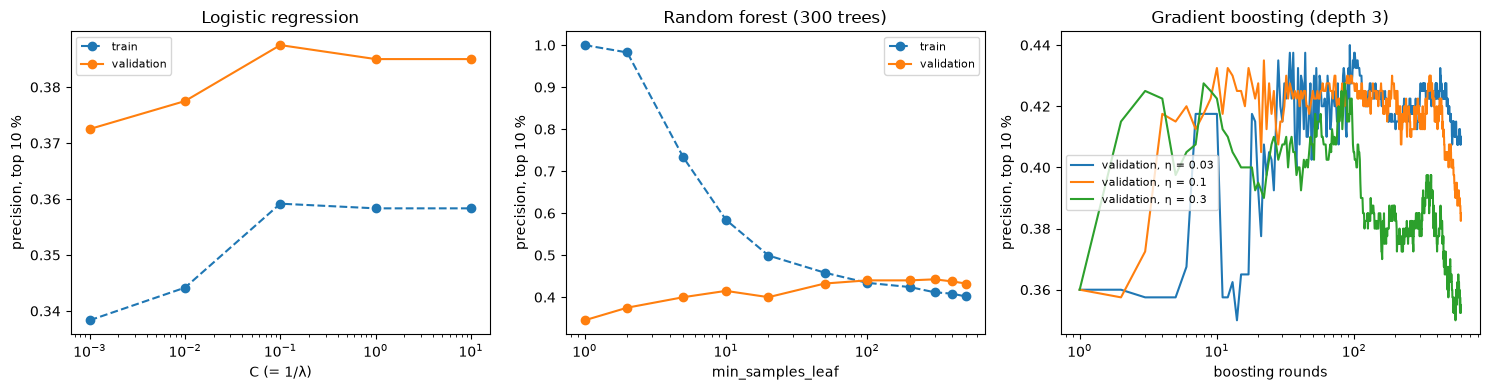

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(valores_C, lr_train, 'o--', label='train')
axes[0].plot(valores_C, lr_val, 'o-', label='validation')
axes[0].set_xscale('log'); axes[0].set_xlabel('C (= 1/λ)'); axes[0].set_title('Logistic regression')

axes[1].plot(valores_hoja, rf_train, 'o--', label='train')
axes[1].plot(valores_hoja, rf_val, 'o-', label='validation')
axes[1].set_xscale('log'); axes[1].set_xlabel('min_samples_leaf'); axes[1].set_title('Random forest (300 trees)')

for eta in [0.03, 0.1, 0.3]:
    axes[2].plot(rondas, gb_curvas_val[eta], label='validation, η = ' + str(eta))
axes[2].set_xscale('log'); axes[2].set_xlabel('boosting rounds'); axes[2].set_title('Gradient boosting (depth 3)')

for ax in axes:
    ax.set_ylabel('precision, top 10 %')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/Hyperparameters.png", dpi=150)
plt.show()

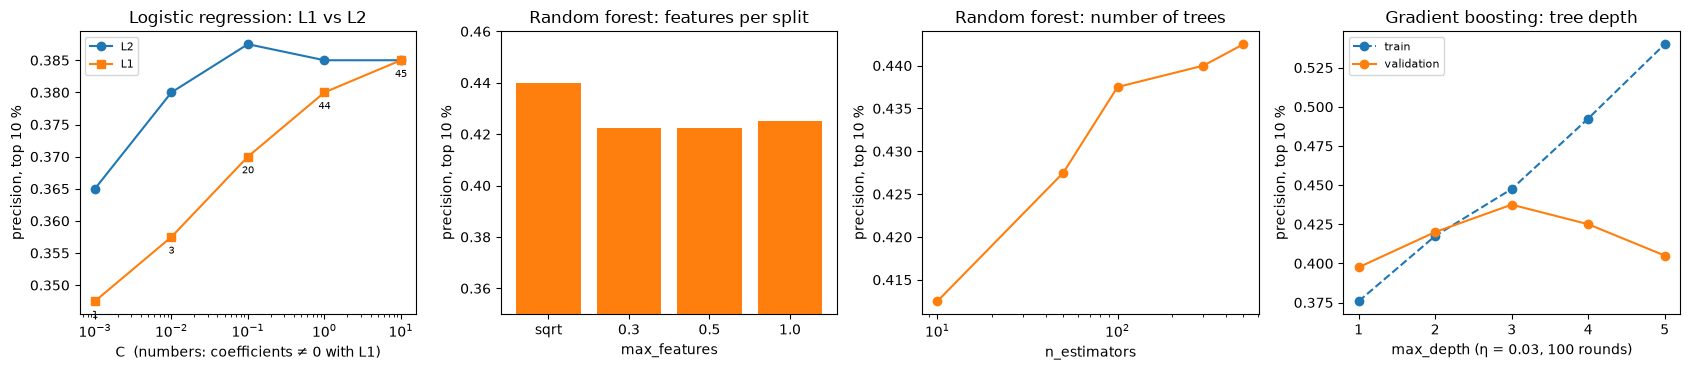

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))

axes[0].plot(valores_C, lr_l2_val, 'o-', label='L2')
axes[0].plot(valores_C, lr_l1_val, 's-', label='L1')
for i in range(len(valores_C)):          # escribo debajo de cada punto L1 cuántos pesos quedan distintos de 0
    axes[0].annotate(str(lr_l1_no_cero[i]), (valores_C[i], lr_l1_val[i]), textcoords='offset points',
                     xytext=(0, -12), ha='center', fontsize=7)
axes[0].set_xscale('log'); axes[0].set_xlabel('C  (numbers: coefficients ≠ 0 with L1)')
axes[0].set_title('Logistic regression: L1 vs L2')

axes[1].bar([str(v) for v in valores_max_feat], rf_max_feat_val, color='tab:orange')
axes[1].set_ylim(0.35, 0.46); axes[1].set_xlabel('max_features'); axes[1].set_title('Random forest: features per split')

axes[2].plot(valores_arboles, rf_arboles_val, 'o-', color='tab:orange')
axes[2].set_xscale('log'); axes[2].set_xlabel('n_estimators'); axes[2].set_title('Random forest: number of trees')

axes[3].plot(valores_profundidad, gb_prof_train, 'o--', label='train')
axes[3].plot(valores_profundidad, gb_prof_val, 'o-', label='validation')
axes[3].set_xlabel('max_depth (η = 0.03, 100 rounds)'); axes[3].set_title('Gradient boosting: tree depth')

for ax in axes:
    ax.set_ylabel('precision, top 10 %')
axes[0].legend(fontsize=8); axes[3].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/Hyperparameters_2.png", dpi=150)
plt.show()

### 24. Modelos elegidos y evaluación final en test (una sola vez)

Además de la precisión del 10 %, calculo la AP (average precision, el área bajo la curva precisión-recall) en validación y test: resume la precisión en todos los umbrales, así que sirve para comprobar si el empate entre modelos depende de haber elegido el 10 %.

In [39]:
# Los modelos elegidos, cada uno con su preprocesador en un Pipeline
modelos_finales = {
    'Dummy': DummyClassifier(strategy='prior'),
    'Logistic regression': LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000),
    'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=100, n_jobs=-1, random_state=SEMILLA),
    'Gradient boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.03, max_depth=3,
                                                    random_state=SEMILLA),
}
tres_modelos = ['Logistic regression', 'Random forest', 'Gradient boosting']   # los mismos sin el Dummy

pipelines_finales = {}
tabla_final = []
for nombre, modelo in modelos_finales.items():
    pipe = Pipeline([('prep', clone(preprocesador_A)), ('modelo', modelo)])
    pipe.fit(X_train, y_train_bin)
    pipelines_finales[nombre] = pipe

    prob_train = pipe.predict_proba(X_train)[:, 1]
    prob_val = pipe.predict_proba(X_val)[:, 1]
    prob_test = pipe.predict_proba(X_test)[:, 1]
    tabla_final.append({'Modelo': nombre,
                        'Train': precision_top10(prob_train, y_train_bin),
                        'Validación': precision_top10(prob_val, y_val_bin),
                        'Test': precision_top10(prob_test, y_test_bin),
                        'AP validación': average_precision_score(y_val_bin, prob_val),
                        'AP test': average_precision_score(y_test_bin, prob_test)})
print(pd.DataFrame(tabla_final).round(3).to_string(index=False))

             Modelo  Train  Validación  Test  AP validación  AP test
              Dummy  0.197       0.190 0.170          0.198    0.198
Logistic regression  0.359       0.388 0.395          0.326    0.321
      Random forest  0.434       0.440 0.422          0.368    0.358
  Gradient boosting  0.448       0.438 0.422          0.372    0.363


### 25. Elegir un umbral para cada modelo elegido (en validación)
Repito la lista de umbrales del paso 17, ahora con los modelos elegidos, para fijar el umbral que usaría la clínica.
Para cada modelo me quedo con el umbral de la lista que marca un número de citas parecido al 10 % (400).

In [40]:
umbral_elegido = {}
for nombre in tres_modelos:
    prob_val = pipelines_finales[nombre].predict_proba(X_val)[:, 1]
    marcadas, precisiones = [], []
    for u in umbrales:
        pred = (prob_val >= u).astype(int)
        marcadas.append(pred.sum())
        precisiones.append(precision_score(y_val_bin, pred, zero_division=0))

    # Elijo el umbral de la lista cuyo número de citas marcadas está más cerca de 400
    menor_distancia = 4000
    for i in range(len(umbrales)):
        distancia = abs(marcadas[i] - 400)
        if distancia < menor_distancia:
            menor_distancia = distancia
            umbral_elegido[nombre] = umbrales[i]

    print(nombre)
    print(pd.DataFrame({'umbral': umbrales, 'marcadas': marcadas, 'precisión': precisiones}).round(3).to_string(index=False))
    print("-> umbral elegido:", umbral_elegido[nombre])
    print()

# Evaluación en test con el umbral elegido en validación
for nombre in tres_modelos:
    prob_test = pipelines_finales[nombre].predict_proba(X_test)[:, 1]
    pred = (prob_test >= umbral_elegido[nombre]).astype(int)
    print(nombre, "| umbral", umbral_elegido[nombre], "-> test: marcadas", pred.sum(),
          "| precisión", round(precision_score(y_test_bin, pred), 3), "| recall", round(recall_score(y_test_bin, pred), 3))

Logistic regression
 umbral  marcadas  precisión
   0.05      4000      0.198
   0.10      4000      0.198
   0.15      4000      0.198
   0.20      4000      0.198
   0.25      3970      0.199
   0.30      3800      0.204
   0.35      3390      0.217
   0.40      2703      0.246
   0.45      1996      0.288
   0.50      1455      0.322
   0.55      1053      0.338
   0.60       741      0.359
   0.65       506      0.381
   0.70       311      0.373
   0.75       176      0.369
   0.80        95      0.358
   0.85        46      0.435
   0.90        16      0.438
   0.95         6      0.500
-> umbral elegido: 0.7

Random forest
 umbral  marcadas  precisión
   0.05      4000      0.198
   0.10      2992      0.253
   0.15      2642      0.280
   0.20      2319      0.296
   0.25      1455      0.337
   0.30       339      0.460
   0.35         0      0.000
   0.40         0      0.000
   0.45         0      0.000
   0.50         0      0.000
   0.55         0      0.000
   0.60       

### 26. Diagnóstico en test: curvas precisión-recall y matrices de confusión
La curva precisión-recall muestra la precisión para cada número de citas marcadas (no solo el 10 %).
La matriz de confusión se calcula con el umbral elegido en validación para cada modelo.

Logistic regression -> TN: 3025 | FP: 185 | FN: 673 | TP: 117
Random forest -> TN: 3027 | FP: 183 | FN: 659 | TP: 131
Gradient boosting -> TN: 2870 | FP: 340 | FN: 555 | TP: 235


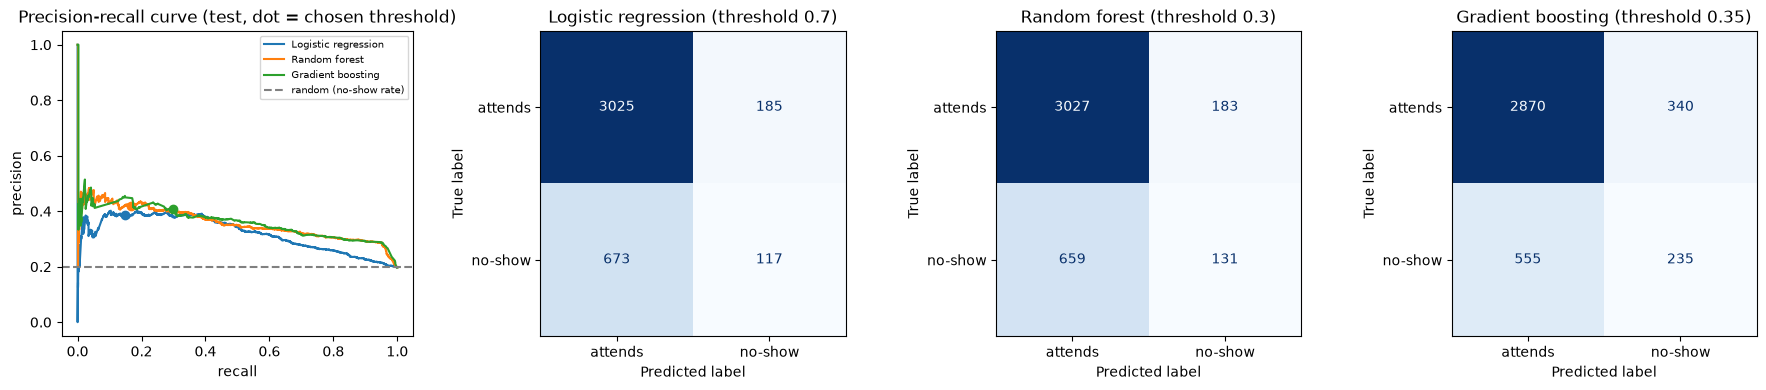

In [41]:
from sklearn.metrics import precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

colores = {'Logistic regression': 'tab:blue', 'Random forest': 'tab:orange', 'Gradient boosting': 'tab:green'}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

#  curva precisión-recall de cada modelo en test, con un punto en su umbral elegido
for nombre in tres_modelos:
    prob_test = pipelines_finales[nombre].predict_proba(X_test)[:, 1]
    precision_curva, recall_curva, _ = precision_recall_curve(y_test_bin, prob_test)   # un punto por umbral
    axes[0].plot(recall_curva, precision_curva, label=nombre, color=colores[nombre])
    pred = (prob_test >= umbral_elegido[nombre]).astype(int)
    axes[0].plot(recall_score(y_test_bin, pred), precision_score(y_test_bin, pred), 'o', color=colores[nombre])
axes[0].axhline(y_test_bin.mean(), color='grey', linestyle='--', label='random (no-show rate)')
axes[0].set_xlabel('recall'); axes[0].set_ylabel('precision'); axes[0].set_title('Precision-recall curve (test, dot = chosen threshold)')
axes[0].legend(fontsize=7)

# matriz de confusión de cada modelo con su umbral
panel = 1
for nombre in tres_modelos:
    prob_test = pipelines_finales[nombre].predict_proba(X_test)[:, 1]
    pred = (prob_test >= umbral_elegido[nombre]).astype(int)
    matriz = confusion_matrix(y_test_bin, pred)        # [[TN, FP], [FN, TP]]
    print(nombre, "-> TN:", matriz[0, 0], "| FP:", matriz[0, 1], "| FN:", matriz[1, 0], "| TP:", matriz[1, 1])
    ConfusionMatrixDisplay(matriz, display_labels=['attends', 'no-show']).plot(ax=axes[panel], colorbar=False, cmap='Blues')
    axes[panel].set_title(nombre + ' (threshold ' + str(umbral_elegido[nombre]) + ')')
    panel = panel + 1
plt.tight_layout()
plt.savefig("figures/Test_diagnostics.png", dpi=150)
plt.show()

### 27. Importancia de cada variable: permutación (en validación)

                   Logistic regression  Random forest  Gradient boosting
AwaitingTime_days                0.162          0.171              0.185
Age                              0.031          0.071              0.066
Neighbourhood                    0.016          0.030              0.022
Hipertension                     0.000          0.018              0.000
Scheduled_Hour                   0.033          0.017              0.005
Scholarship                      0.005          0.007              0.005
Handcap                          0.001          0.002              0.003
Diabetes                        -0.000          0.001              0.000
Alcoholism                       0.008         -0.000              0.010
Gender                           0.004         -0.003              0.000


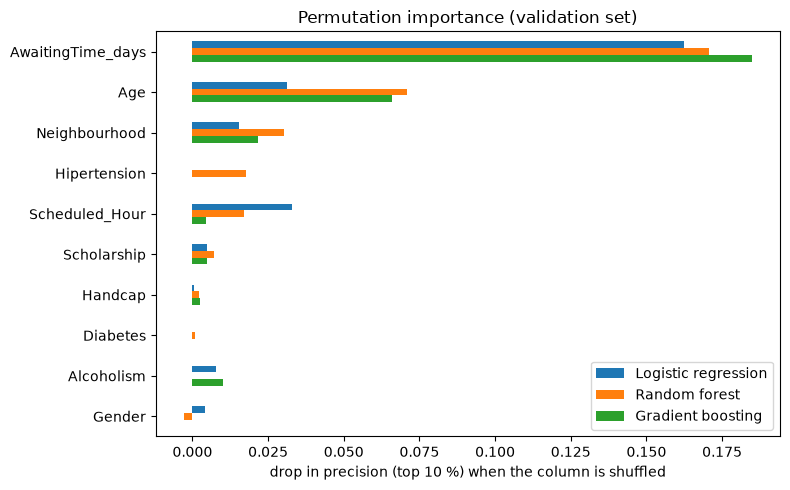

In [42]:
def puntuacion(modelo, X, y):
    return precision_top10(modelo.predict_proba(X)[:, 1], y)

importancias = {}
for nombre in tres_modelos:
    resultado = permutation_importance(pipelines_finales[nombre], X_val, y_val_bin, scoring=puntuacion,
                                       n_repeats=10, random_state=SEMILLA, n_jobs=-1)
    importancias[nombre] = resultado.importances_mean

tabla_importancias = pd.DataFrame(importancias, index=X_val.columns)
tabla_importancias = tabla_importancias.sort_values('Random forest', ascending=False)
print(tabla_importancias.round(3))

tabla_importancias.plot.barh(figsize=(8, 5))
plt.gca().invert_yaxis()
plt.xlabel('drop in precision (top 10 %) when the column is shuffled')
plt.title('Permutation importance (validation set)')
plt.tight_layout()
plt.savefig("figures/Permutation_importance.png", dpi=150)
plt.show()

### 28. Prueba con una variable de ruido 
Añado una columna de números aleatorios, que no puede tener relación con el no-show, y comparo la importancia por impureza (la del propio bosque) con la de permutación.

In [43]:
generador = np.random.default_rng(SEMILLA)
X_train_ruido = X_train.copy()
X_val_ruido = X_val.copy()
X_train_ruido['Noise'] = generador.normal(size=len(X_train))
X_val_ruido['Noise'] = generador.normal(size=len(X_val))

# El preprocesador A, con Noise escalada como Age y Scheduled_Hour
prep_ruido = ColumnTransformer([
    ('estandar', StandardScaler(), ['Age', 'Scheduled_Hour', 'Noise']),
    ('robusto', RobustScaler(), ['AwaitingTime_days', 'Handcap']),
    ('bin', OneHotEncoder(drop='if_binary', sparse_output=False), columnas_binarias),
    ('barrio', OneHotEncoder(min_frequency=0.01, handle_unknown='ignore', sparse_output=False), ['Neighbourhood'])
])

for hoja in [1, 100]:
    bosque = Pipeline([('prep', clone(prep_ruido)),
                       ('modelo', RandomForestClassifier(n_estimators=300, min_samples_leaf=hoja,
                                                         n_jobs=-1, random_state=SEMILLA))])
    bosque.fit(X_train_ruido, y_train_bin)

    nombres = list(bosque.named_steps['prep'].get_feature_names_out())
    impureza = bosque.named_steps['modelo'].feature_importances_
    impureza_ruido = impureza[nombres.index('estandar__Noise')]
    puesto = (impureza > impureza_ruido).sum() + 1                 # cuántas columnas tienen más importancia, + 1

    perm = permutation_importance(bosque, X_val_ruido, y_val_bin, scoring=puntuacion,
                                  n_repeats=10, random_state=SEMILLA, n_jobs=-1)
    perm_ruido = perm.importances_mean[list(X_val_ruido.columns).index('Noise')]

    print("min_samples_leaf =", hoja, "-> importancia por impureza del ruido:", round(impureza_ruido, 3),
          "(puesto", puesto, "de", len(nombres), ") | por permutación:", round(perm_ruido, 3))

min_samples_leaf = 1 -> importancia por impureza del ruido: 0.214 (puesto 2 de 48 ) | por permutación: -0.002
min_samples_leaf = 100 -> importancia por impureza del ruido: 0.037 (puesto 4 de 48 ) | por permutación: -0.013


### 29. Pruebas quitando variables (random forest elegido, validación)

In [44]:
precision_todas = precision_top10(pipelines_finales['Random forest'].predict_proba(X_val)[:, 1], y_val_bin)
print("Con todas las variables:", round(precision_todas, 3))

for variable in X_train.columns:
    estandar = ['Age', 'Scheduled_Hour']
    robusto = ['AwaitingTime_days', 'Handcap']
    binarias = ['Gender', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism']
    barrio = ['Neighbourhood']
    for lista in [estandar, robusto, binarias, barrio]:
        if variable in lista:
            lista.remove(variable)

    prep_sin = ColumnTransformer([
        ('estandar', StandardScaler(), estandar),
        ('robusto', RobustScaler(), robusto),
        ('bin', OneHotEncoder(drop='if_binary', sparse_output=False), binarias),
        ('barrio', OneHotEncoder(min_frequency=0.01, handle_unknown='ignore', sparse_output=False), barrio)
    ])
    bosque = Pipeline([('prep', prep_sin),
                       ('modelo', RandomForestClassifier(n_estimators=300, min_samples_leaf=100,
                                                         n_jobs=-1, random_state=SEMILLA))])
    X_train_sin = X_train.drop(columns=variable)
    X_val_sin = X_val.drop(columns=variable)
    bosque.fit(X_train_sin, y_train_bin)
    print("Sin", variable, "->", round(precision_top10(bosque.predict_proba(X_val_sin)[:, 1], y_val_bin), 3))

Con todas las variables: 0.44
Sin Gender -> 0.422
Sin Age -> 0.402
Sin Neighbourhood -> 0.415
Sin Scholarship -> 0.438
Sin Hipertension -> 0.432
Sin Diabetes -> 0.425
Sin Alcoholism -> 0.435
Sin Handcap -> 0.428
Sin AwaitingTime_days -> 0.278
Sin Scheduled_Hour -> 0.415


### 30. Prueba: añadir el historial de asistencia de cada paciente (random forest elegido, validación)
Al quedarme con una cita por paciente pierdo su historial. Aquí recupero cuántas veces faltó antes cada paciente, con las 109.903 citas válidas, y miro si el mejor modelo mejora.
Para no usar información del futuro, solo cuento las citas de ese paciente cuyo día de consulta es anterior al día en que reservó la cita que quiero predecir.

In [45]:

filas = list(X_train.index) + list(X_val.index)                 # las citas de train y validación
pacientes = df_muestra.loc[filas, 'PatientId']
citas_de_esos_pacientes = df_filtrado[df_filtrado['PatientId'].isin(pacientes)]   # para buscar más rápido

lista_faltas = []
for fila in filas:
    paciente = df_muestra.loc[fila, 'PatientId']
    dia_reserva = df_muestra.loc[fila, 'ScheduledDay_dt'].normalize()          # día en que se reservó esta cita
    sus_citas = citas_de_esos_pacientes[citas_de_esos_pacientes['PatientId'] == paciente]
    anteriores = sus_citas[sus_citas['AppointmentDay_dt'] < dia_reserva]          # citas ya pasadas al reservar
    lista_faltas.append((anteriores['No-show'] == 'Yes').sum())                  # a cuántas no fue
faltas_previas = pd.Series(lista_faltas, index=filas)

X_train_hist = X_train.copy()
X_val_hist = X_val.copy()
X_train_hist['Prev_noshows'] = faltas_previas
X_val_hist['Prev_noshows'] = faltas_previas

print("Citas de train con algún no-show anterior:", round((X_train_hist['Prev_noshows'] > 0).mean() * 100, 1), "%")

# % de no-show en train según los no-shows anteriores
cero = X_train_hist['Prev_noshows'] == 0
uno = X_train_hist['Prev_noshows'] == 1
dos_o_mas = X_train_hist['Prev_noshows'] >= 2
print("No-shows anteriores = 0 -> citas:", cero.sum(), "| % de no-show:", round(y_train_bin[cero].mean() * 100, 1))
print("No-shows anteriores = 1 -> citas:", uno.sum(), "| % de no-show:", round(y_train_bin[uno].mean() * 100, 1))
print("No-shows anteriores = 2 o más -> citas:", dos_o_mas.sum(), "| % de no-show:", round(y_train_bin[dos_o_mas].mean() * 100, 1))

prep_hist = ColumnTransformer([
    ('estandar', StandardScaler(), ['Age', 'Scheduled_Hour']),
    ('robusto', RobustScaler(), ['AwaitingTime_days', 'Handcap', 'Prev_noshows']),
    ('bin', OneHotEncoder(drop='if_binary', sparse_output=False), columnas_binarias),
    ('barrio', OneHotEncoder(min_frequency=0.01, handle_unknown='ignore', sparse_output=False), ['Neighbourhood'])
])
bosque_hist = Pipeline([('prep', prep_hist),
                        ('modelo', RandomForestClassifier(n_estimators=300, min_samples_leaf=100,
                                                          n_jobs=-1, random_state=SEMILLA))])
bosque_hist.fit(X_train_hist, y_train_bin)

precision_sin = precision_top10(pipelines_finales['Random forest'].predict_proba(X_val)[:, 1], y_val_bin)
precision_con = precision_top10(bosque_hist.predict_proba(X_val_hist)[:, 1], y_val_bin)
print("Random forest sin historial -> validación:", round(precision_sin, 3))
print("Random forest con historial -> validación:", round(precision_con, 3))

Citas de train con algún no-show anterior: 3.7 %
No-shows anteriores = 0 -> citas: 11553 | % de no-show: 19.7
No-shows anteriores = 1 -> citas: 388 | % de no-show: 19.6
No-shows anteriores = 2 o más -> citas: 59 | % de no-show: 25.4
Random forest sin historial -> validación: 0.44
Random forest con historial -> validación: 0.425


### 31. Dónde falla el mejor modelo (test, después de la evaluación final)

In [46]:
mejor = pipelines_finales['Random forest']
prob_test = mejor.predict_proba(X_test)[:, 1]
marcada = (prob_test >= umbral_elegido['Random forest']).astype(int)
real = y_test_bin.values

print("Aciertos (TP):", ((marcada == 1) & (real == 1)).sum(),
      "| Falsos positivos (FP):", ((marcada == 1) & (real == 0)).sum(),
      "| No-shows no detectados (FN):", ((marcada == 0) & (real == 1)).sum())

# Por tramos de espera: para cada tramo cuento citas, no-shows, citas marcadas y aciertos
espera = X_test['AwaitingTime_days'].values
tramos = [('0', 0, 0), ('1-3', 1, 3), ('4-7', 4, 7), ('8-15', 8, 15), ('16-30', 16, 30), ('>30', 31, 200)]
filas = []
for etiqueta, desde, hasta in tramos:
    en_tramo = (espera >= desde) & (espera <= hasta)
    citas = en_tramo.sum()
    no_shows = (en_tramo & (real == 1)).sum()
    marcadas = (en_tramo & (marcada == 1)).sum()
    aciertos = (en_tramo & (marcada == 1) & (real == 1)).sum()
    if marcadas > 0:
        precision_tramo = round(aciertos / marcadas, 2)
    else:
        precision_tramo = None
    filas.append({'tramo': etiqueta, 'Citas': citas, 'No-shows': no_shows, 'Marcadas': marcadas,
                  'Aciertos': aciertos, 'Precisión': precision_tramo})
print(pd.DataFrame(filas).to_string(index=False))

Aciertos (TP): 131 | Falsos positivos (FP): 183 | No-shows no detectados (FN): 659
tramo  Citas  No-shows  Marcadas  Aciertos  Precisión
    0   1381        39         0         0        NaN
  1-3    507       115         0         0        NaN
  4-7    559       141         1         0       0.00
 8-15    473       130        68        24       0.35
16-30    633       198       128        53       0.41
  >30    447       167       117        54       0.46
